# Hypothese 3: Spart man pro qm mit durchschnittlicher Bauqualität?
EDA King County House Sales · Kunde: Thomas Hansen (5 Kinder, wenig Budget, braucht vor allem Fläche)

**Hypothese:** Häuser mit durchschnittlicher Bauqualität (Grade 7) sind im Median pro qm deutlich günstiger (mind. 15 %) als Häuser mit gehobener Bauqualität (Grade 9–10).

**Gliederung**
1. Daten
2. Vorbereitung: Gruppen bilden
3. Daten erkunden
4. Zusammenhänge
5. Hypothese prüfen: Gesamtmarkt
6. Folgefrage: fairer Vergleich (gleiche PLZ, gleiche Größe)
7. Preisvergleich je Postleitzahl
8. Fazit

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["text.parse_math"] = False  # "$" ist hier Währung, keine Formel
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
Path("output").mkdir(exist_ok=True)


# Zahlen im deutschen Format ausgeben (1.234,5)
def de(zahl, stellen=0):
    return f"{zahl:,.{stellen}f}".replace(",", "X").replace(".", ",").replace("X", ".")


# p-Werte in wissenschaftlicher Schreibweise mit Komma (z. B. 2,1e-06)
def p_de(p):
    return f"{p:.1e}".replace(".", ",")


# Kasten mit Kennzahlen direkt ins Diagramm schreiben
def kennzahlen(ax, text, x=0.98, y=0.97, ha="right", va="top"):
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=10,
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9))


MONATE = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

---
## 1. Daten
Wir arbeiten mit dem bereinigten Datensatz aus `04_eda_data_cleaning` (Hausverkäufe in King County, Washington).

In [12]:
# Daten wurden in 03_fetching_the_data_eda per SQL geholt und in 04_eda_data_cleaning bereinigt
df = pd.read_csv("data/eda_tk_cleaned.csv", parse_dates=["date"])
print("Zeilen, Spalten:", df.shape)
print("Zeitraum:", df["date"].min().date(), "bis", df["date"].max().date())
df.head()

Zeilen, Spalten: (21597, 26)
Zeitraum: 2014-05-02 bis 2015-05-27


,sale_id,house_id,date,price,bedrooms,bathrooms,qm_living,qm_lot,floors,waterfront,...,yr_renovated,zipcode,lat,long,qm_living15,qm_lot15,yr_renovated_unbekannt,keller_typ,preis_pro_qm_wohnflaeche,preis_pro_qm_grundstueck
0,1,7129300520,2014-10-13,"221,900.00",3,1.00,109.63,524.90,1.00,0,...,0,98178,47.51,-122.26,124.49,524.90,False,Kein Keller (0 qm),"2,024.08",422.75
1,2,6414100192,2014-12-09,"538,000.00",3,2.25,238.76,672.80,2.00,0,...,1991,98125,47.72,-122.32,157.01,709.69,False,Nutzbarer Keller (>= 5 qm),"2,253.31",799.64
2,3,5631500400,2015-02-25,"180,000.00",2,1.00,71.54,929.03,1.00,0,...,0,98028,47.74,-122.23,252.70,748.98,True,Kein Keller (0 qm),"2,516.07",193.75
3,4,2487200875,2014-12-09,"604,000.00",4,3.00,182.09,464.52,1.00,0,...,0,98136,47.52,-122.39,126.35,464.52,False,Nutzbarer Keller (>= 5 qm),"3,317.04","1,300.27"
4,5,1954400510,2015-02-18,"510,000.00",3,2.00,156.08,750.66,1.00,0,...,0,98074,47.62,-122.05,167.23,697.05,False,Kein Keller (0 qm),"3,267.56",679.40


In [13]:
spalten = ["price", "qm_living", "preis_pro_qm_wohnflaeche", "grade", "yr_built", "zipcode"]
print(df[spalten].dtypes, "\n")
print("Fehlende Werte je Spalte:\n", df[spalten].isna().sum())
print("\nHäufigkeit grade:\n", df["grade"].value_counts().sort_index())
df[spalten].describe()

price                       float64
qm_living                   float64
preis_pro_qm_wohnflaeche    float64
grade                         int64
yr_built                      int64
zipcode                       int64
dtype: object 

Fehlende Werte je Spalte:
 price                       0
qm_living                   0
preis_pro_qm_wohnflaeche    0
grade                       0
yr_built                    0
zipcode                     0
dtype: int64

Häufigkeit grade:
 grade
3        1
4       27
5      242
6     2038
7     8974
8     6065
9     2615
10    1134
11     399
12      89
13      13
Name: count, dtype: int64


,price,qm_living,preis_pro_qm_wohnflaeche,grade,yr_built,zipcode
count,"21,597.00","21,597.00","21,597.00","21,597.00","21,597.00","21,597.00"
mean,"540,296.57",193.27,"2,843.22",7.66,"1,971.00","98,077.95"
std,"367,368.14",85.29,"1,184.03",1.17,29.38,53.51
min,"78,000.00",34.37,942.76,3.00,"1,900.00","98,001.00"
25%,"322,000.00",132.85,"1,962.18",7.00,"1,951.00","98,033.00"
50%,"450,000.00",177.44,"2,633.27",7.00,"1,975.00","98,065.00"
75%,"645,000.00",236.90,"3,426.57",8.00,"1,997.00","98,118.00"
max,"7,700,000.00","1,257.91","8,719.85",13.00,"2,015.00","98,199.00"


**Was finden wir vor?**
- 21.597 Verkäufe aus den Jahren 2014/15, **keine fehlenden Werte** in den Spalten, die wir brauchen.
- Wichtig für uns:
  - `grade` = Bauqualität laut Bewertung des King County Assessor, **geordnet kategorial** von 3 (sehr einfach) bis 13 (Luxus)
  - `preis_pro_qm_wohnflaeche` = Preis geteilt durch Wohnfläche (stetig) → unsere Zielgröße
  - `qm_living` und `zipcode` brauchen wir für den fairen Vergleich (gleiche Größe, gleiche Lage)
  - `yr_built` = Baujahr, zur Einordnung
- Grade 7 ist mit 8.974 Verkäufen die häufigste Stufe, danach kommt Grade 8 (6.065). Grade 9 und 10 kommen zusammen auf 3.749 Verkäufe. Beide Vergleichsgruppen sind also groß genug.

---
## 2. Vorbereitung: Gruppen bilden
**Unsere Annahmen** (laut Glossar des King County Assessor für `grade`):
- **Durchschnittlich** = Grade 7 („Average grade of construction and design“).
- **Gehoben** = Grade 9–10 („Better architectural design“, „high quality features“). Grade 8 ist eine Zwischenstufe, 11–13 ist Luxus. Beide lassen wir weg, damit die Gruppen klar getrennt sind.
- **Pro qm** = Preis ÷ Wohnfläche.
- **Deutlich** = mindestens **15 %** günstiger. Die Baukosten zwischen mittlerer und gehobener Ausstattung unterscheiden sich laut deutschen Normalherstellungskosten (NHK 2010) um ca. 17 %. Wir runden vorsichtig ab.

Gruppe
durchschnittlich (7)    8974
gehoben (9–10)          3749
Name: count, dtype: int64
Nicht im Vergleich (Grade 3–6, 8, 11–13): 8.874 Verkäufe (nicht gelöscht, nur nicht verglichen)


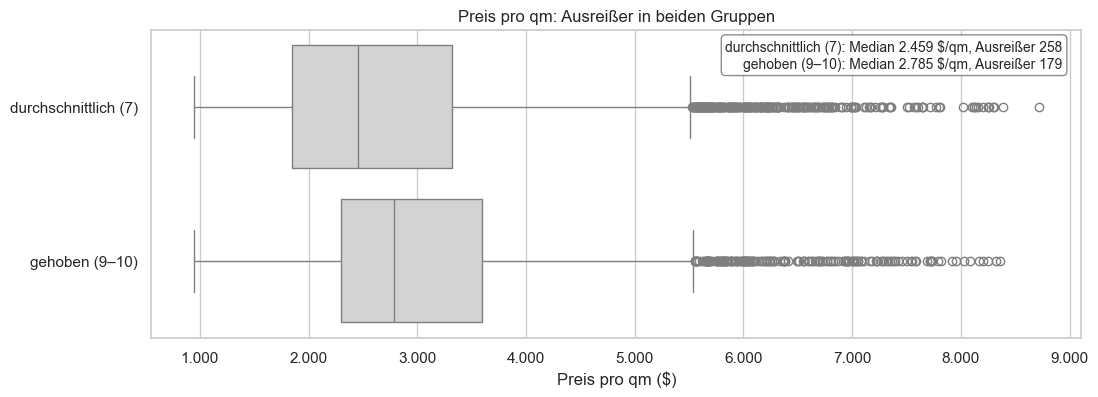

In [14]:
df["qm_preis"] = df["preis_pro_qm_wohnflaeche"]
vergleich = df[df["grade"].isin([7, 9, 10])].copy()
vergleich["Gruppe"] = np.where(vergleich["grade"] == 7, "durchschnittlich (7)", "gehoben (9–10)")

print(vergleich["Gruppe"].value_counts())
print(f"Nicht im Vergleich (Grade 3–6, 8, 11–13): {de(len(df) - len(vergleich))} Verkäufe (nicht gelöscht, nur nicht verglichen)")

# Ausreißer je Gruppe nach der 1,5-IQR-Regel
def anzahl_ausreisser(werte):
    q1, q3 = werte.quantile([0.25, 0.75])
    return (werte > q3 + 1.5 * (q3 - q1)).sum()

ausreisser = vergleich.groupby("Gruppe")["qm_preis"].apply(anzahl_ausreisser)

fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=vergleich, x="qm_preis", y="Gruppe", color="lightgray", ax=ax)
ax.set_title("Preis pro qm: Ausreißer in beiden Gruppen")
ax.set_xlabel("Preis pro qm ($)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(lambda x, _: de(x))
kennzahlen(ax, "\n".join(f"{g}: Median {de(m)} $/qm, Ausreißer {de(ausreisser[g])}"
                         for g, m in vergleich.groupby("Gruppe")["qm_preis"].median().items()))
plt.show()

**Kennzahlen:** Grade 7: n = 8.974, Median 2.459 $/qm, 258 Ausreißer · Grade 9–10: n = 3.749, Median 2.785 $/qm, 179 Ausreißer (1,5-IQR-Regel)

**Entscheidung:** Beide Gruppen haben teure Ausreißer (z. B. Häuser am See). Das sind echte Verkäufe. Weil wir **Mediane** vergleichen, **löschen wir nichts**. Was schon hier auffällt: Die beiden Boxen liegen **gar nicht weit auseinander**.

---
## 3. Daten erkunden
Wir vergleichen die Verteilungen beider Gruppen. Weil die Gruppen unterschiedlich groß sind, zeigen wir die **Dichte** statt der Anzahl. So kann man die Form direkt vergleichen.

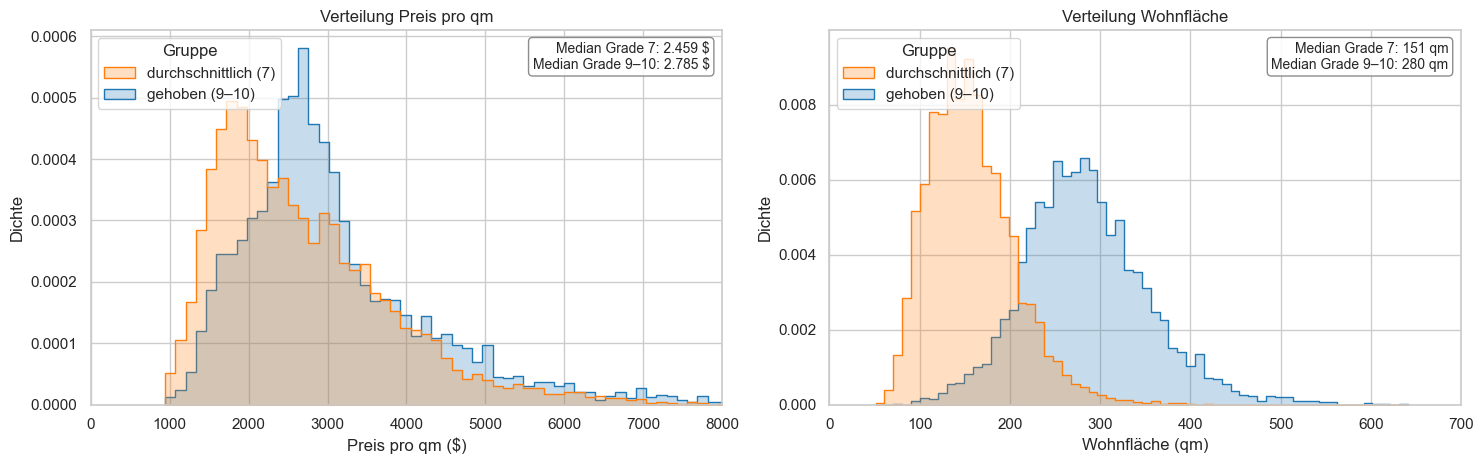

                      Preis pro qm      Preis  Wohnfläche  Baujahr
Gruppe                                                            
durchschnittlich (7)      2,459.02 375,000.00      151.43 1,963.00
gehoben (9–10)            2,784.99 775,000.00      279.64 1,995.00


In [15]:
farben = {"durchschnittlich (7)": "tab:orange", "gehoben (9–10)": "tab:blue"}
mediane = vergleich.groupby("Gruppe")[["qm_preis", "price", "qm_living", "yr_built"]].median()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(data=vergleich, x="qm_preis", hue="Gruppe", bins=60, stat="density", common_norm=False,
             element="step", palette=farben, ax=axes[0])
axes[0].set_title("Verteilung Preis pro qm")
axes[0].set_xlabel("Preis pro qm ($)")
axes[0].set_ylabel("Dichte")
axes[0].set_xlim(0, 8000)
sns.move_legend(axes[0], "upper left")
kennzahlen(axes[0], f"Median Grade 7: {de(mediane.loc['durchschnittlich (7)', 'qm_preis'])} $\n"
                    f"Median Grade 9–10: {de(mediane.loc['gehoben (9–10)', 'qm_preis'])} $")

sns.histplot(data=vergleich, x="qm_living", hue="Gruppe", bins=60, stat="density", common_norm=False,
             element="step", palette=farben, ax=axes[1])
axes[1].set_title("Verteilung Wohnfläche")
axes[1].set_xlabel("Wohnfläche (qm)")
axes[1].set_ylabel("Dichte")
axes[1].set_xlim(0, 700)
sns.move_legend(axes[1], "upper left")
kennzahlen(axes[1], f"Median Grade 7: {de(mediane.loc['durchschnittlich (7)', 'qm_living'])} qm\n"
                    f"Median Grade 9–10: {de(mediane.loc['gehoben (9–10)', 'qm_living'])} qm")
plt.tight_layout()
plt.show()

print(mediane.rename(columns={"qm_preis": "Preis pro qm", "price": "Preis", "qm_living": "Wohnfläche", "yr_built": "Baujahr"}))

**Kennzahlen (Mediane)**

| | Preis pro qm | Preis | Wohnfläche | Baujahr |
|---|---|---|---|---|
| durchschnittlich (Grade 7) | 2.459 $ | 375.000 $ | 151 qm | 1963 |
| gehoben (Grade 9–10) | 2.785 $ | 775.000 $ | 280 qm | 1995 |

**Was bedeutet das?**
- Beim **qm-Preis** überlappen sich die beiden Gruppen stark.
- Bei der **Wohnfläche** sind sie dagegen völlig verschieden: Gehobene Häuser sind im Median fast **doppelt so groß** und rund 30 Jahre jünger.
- Ein einfacher Gesamtvergleich vergleicht also nicht nur die Ausstattung, sondern auch **kleine mit großen Häusern**.

---
## 4. Zusammenhänge
**Methode:** Spearman-Korrelationsmatrix über alle Verkäufe. Spearman passt hier, weil `grade` eine Rangskala ist (geordnete Kategorien) und die Preise schief verteilt sind.

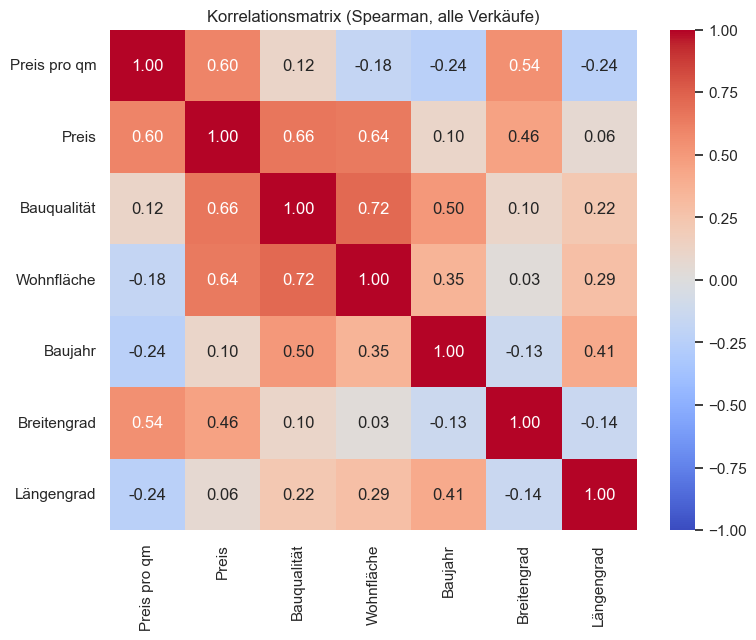

Korrelation mit Bauqualität:
Wohnfläche     0.72
Preis          0.66
Baujahr        0.50
Längengrad     0.22
Preis pro qm   0.12
Breitengrad    0.10
Name: Bauqualität, dtype: float64


In [16]:
namen = {"qm_preis": "Preis pro qm", "price": "Preis", "grade": "Bauqualität", "qm_living": "Wohnfläche",
         "yr_built": "Baujahr", "lat": "Breitengrad", "long": "Längengrad"}
korr = df[list(namen)].corr(method="spearman").rename(index=namen, columns=namen)

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(korr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Korrelationsmatrix (Spearman, alle Verkäufe)")
plt.show()

print("Korrelation mit Bauqualität:")
print(korr["Bauqualität"].drop("Bauqualität").sort_values(ascending=False).round(2))

**Kennzahlen (Korrelation mit der Bauqualität):** Wohnfläche 0,72 · Preis 0,66 · Baujahr 0,50 · Längengrad 0,22 · **Preis pro qm nur 0,12** · Breitengrad 0,10

**Was bedeutet das?** Die Bauqualität hängt stark mit dem **Gesamtpreis** zusammen, mit dem **qm-Preis** aber viel schwächer. Der Grund: Bessere Häuser sind meistens auch **größer**, und große Häuser sind pro qm eher günstiger. Die Größe verdeckt also einen Teil des Qualitätseffekts. Das prüfen wir im nächsten Diagramm, indem wir nur gleich große Häuser vergleichen.

Gruppe   durchschnittlich (7)  gehoben (9–10)  Abschlag (%)
groesse                                                    
< 150                2,928.60        4,458.00         34.30
150–200              2,236.00        3,519.30         36.50
200–250              2,019.70        2,913.90         30.70
250–300              1,873.40        2,740.60         31.60
> 300                1,686.20        2,629.80         35.90


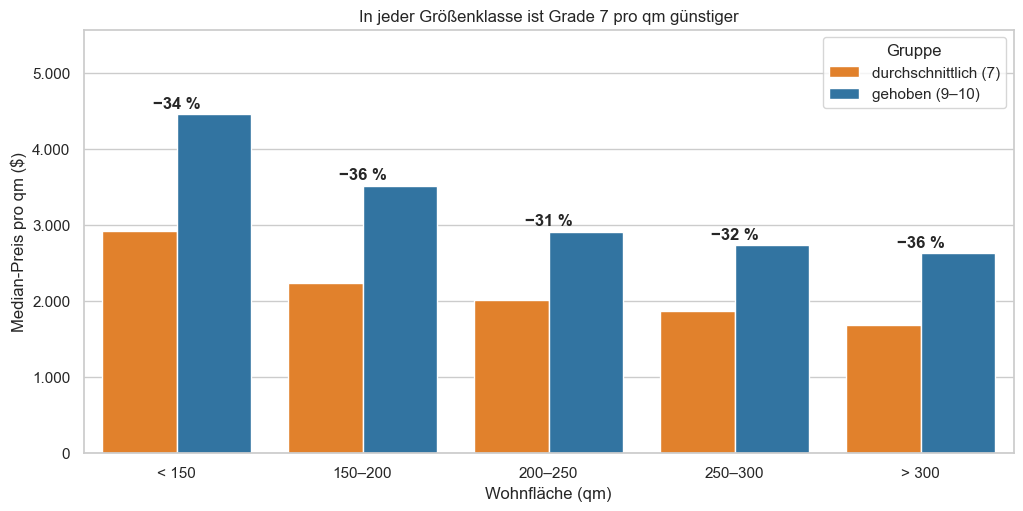

In [17]:
vergleich["groesse"] = pd.cut(vergleich["qm_living"], [0, 150, 200, 250, 300, 2000],
                              labels=["< 150", "150–200", "200–250", "250–300", "> 300"])
je_groesse = vergleich.pivot_table(index="groesse", columns="Gruppe", values="qm_preis",
                                   aggfunc="median", observed=True)
je_groesse["Abschlag (%)"] = 100 * (1 - je_groesse["durchschnittlich (7)"] / je_groesse["gehoben (9–10)"])
print(je_groesse.round(1))

plt.figure(figsize=(12, 5.5))
ax = sns.barplot(data=vergleich, x="groesse", y="qm_preis", hue="Gruppe", estimator="median",
                 errorbar=None, palette=farben)
for i, a in enumerate(je_groesse["Abschlag (%)"]):
    ax.text(i, je_groesse.iloc[i, :2].max() + 80, f"−{de(a)} %", ha="center", weight="bold")
plt.title("In jeder Größenklasse ist Grade 7 pro qm günstiger")
plt.xlabel("Wohnfläche (qm)")
plt.ylabel("Median-Preis pro qm ($)")
ax.yaxis.set_major_formatter(lambda y, _: de(y))
ax.set_ylim(0, je_groesse.iloc[:, :2].max().max() * 1.25)
sns.move_legend(ax, "upper right", title="Gruppe")
plt.show()

**Kennzahlen (Abschlag Grade 7 gegenüber gehoben, je Größenklasse):** unter 150 qm: 34 % · 150–200 qm: 36 % · 200–250 qm: 31 % · 250–300 qm: 32 % · über 300 qm: 36 %

**Was bedeutet das?** Vergleicht man **gleich große** Häuser, ist Grade 7 in **jeder** Größenklasse rund ein Drittel günstiger pro qm, also viel mehr als die 12 % im Gesamtvergleich. Hier ist aber die **Lage** noch nicht herausgerechnet: Gehobene Häuser stehen häufiger in teuren Gegenden (siehe Hypothese 2). Ein fairer Vergleich muss also Größe **und** Lage berücksichtigen, das machen wir in Abschnitt 6.

---
## 5. Hypothese prüfen: Gesamtmarkt
Zuerst prüfen wir die Hypothese so, wie sie formuliert ist: alle Grade-7-Verkäufe gegen alle gehobenen Verkäufe.
- **Mann-Whitney-U-Test:** Ist Grade 7 pro qm überhaupt systematisch günstiger? Wir nehmen diesen Test, weil die qm-Preise schief verteilt sind und er keine Normalverteilung braucht.
- **Bootstrap (2.000 Ziehungen):** Der Test sagt nur „ja/nein“. Mit dem Bootstrap sehen wir, wie groß der Abschlag mit 95 % Sicherheit **mindestens** ist. Das brauchen wir für die 15-%-Grenze.
- **Zufällige Paare:** Wie oft ist ein zufälliges Grade-7-Haus pro qm günstiger als ein zufälliges gehobenes Haus? Das ist eine leicht verständliche Kennzahl für die Präsentation.

Median qm-Preis Grade 7:    2.459 $  (n = 8.974)
Median qm-Preis Grade 9–10: 2.785 $  (n = 3.749)
Abschlag: 11,7 %  | mit 95 % Sicherheit mindestens 10,6 %
Mann-Whitney p = 1,4e-71
In 60% zufälliger Paare ist das Grade-7-Haus pro qm günstiger
→ deutlich (mind. 15 %)? nein


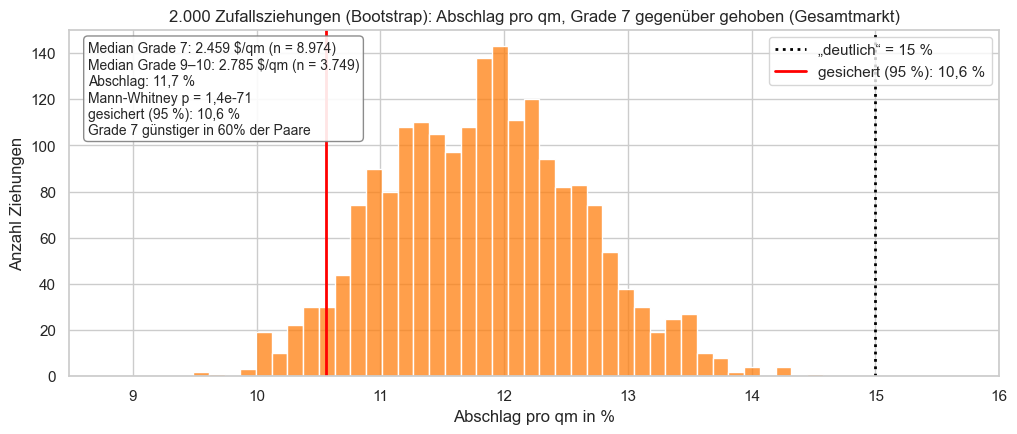

In [18]:
q7 = vergleich.loc[vergleich["grade"] == 7, "qm_preis"]
qg = vergleich.loc[vergleich["grade"] >= 9, "qm_preis"]
abschlag = 100 * (1 - q7.median() / qg.median())
p_wert = stats.mannwhitneyu(q7, qg, alternative="less").pvalue

rng = np.random.default_rng(42)
boot = np.array([100 * (1 - np.median(rng.choice(q7, len(q7))) / np.median(rng.choice(qg, len(qg))))
                 for _ in range(2000)])
gesichert = np.percentile(boot, 5)

# Wie oft ist ein zufälliges Grade-7-Haus pro qm günstiger als ein zufälliges gehobenes?
anteil_guenstiger = np.mean(rng.choice(q7.values, 100_000) < rng.choice(qg.values, 100_000))

print(f"Median qm-Preis Grade 7:    {de(q7.median())} $  (n = {de(len(q7))})")
print(f"Median qm-Preis Grade 9–10: {de(qg.median())} $  (n = {de(len(qg))})")
print(f"Abschlag: {de(abschlag, 1)} %  | mit 95 % Sicherheit mindestens {de(gesichert, 1)} %")
print(f"Mann-Whitney p = {p_de(p_wert)}")
print(f"In {anteil_guenstiger:.0%} zufälliger Paare ist das Grade-7-Haus pro qm günstiger")
print(f"→ deutlich (mind. 15 %)? {'ja' if gesichert >= 15 else 'nein'}")

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.histplot(boot, bins=40, color="tab:orange", ax=ax)
ax.axvline(15, color="black", ls=":", lw=2, label="„deutlich“ = 15 %")
ax.axvline(gesichert, color="red", lw=2, label=f"gesichert (95 %): {de(gesichert, 1)} %")
ax.set_xlim(min(boot.min(), gesichert) - 1, 16)
ax.set_title("2.000 Zufallsziehungen (Bootstrap): Abschlag pro qm, Grade 7 gegenüber gehoben (Gesamtmarkt)")
ax.set_xlabel("Abschlag pro qm in %")
ax.set_ylabel("Anzahl Ziehungen")
ax.legend(loc="upper right")
kennzahlen(ax, f"Median Grade 7: {de(q7.median())} $/qm (n = {de(len(q7))})\n"
               f"Median Grade 9–10: {de(qg.median())} $/qm (n = {de(len(qg))})\n"
               f"Abschlag: {de(abschlag, 1)} %\nMann-Whitney p = {p_de(p_wert)}\n"
               f"gesichert (95 %): {de(gesichert, 1)} %\n"
               f"Grade 7 günstiger in {anteil_guenstiger:.0%} der Paare", x=0.02, ha="left")
plt.show()

**Kennzahlen**

| Kennzahl | Wert |
|---|---|
| Median Grade 7 (n = 8.974) | 2.459 $/qm |
| Median Grade 9–10 (n = 3.749) | 2.785 $/qm |
| Abschlag | 11,7 % |
| Mit 95 % Sicherheit mindestens | 10,6 % |
| Mann-Whitney-U p-Wert | 1,4 · 10⁻⁷¹ (signifikant) |
| Grade 7 günstiger in zufälligen Paaren | 60 % |

**Was bedeutet das?**
- Grade 7 ist pro qm **signifikant günstiger**, aber nur um rund **12 %** (gesichert ca. 11 %).
- In **4 von 10** zufälligen Paaren ist das Grade-7-Haus pro qm sogar **teurer** als das gehobene.
- **Am Gesamtmarkt ist der Unterschied also nicht deutlich (unter 15 %).**

Aber: In Abschnitt 4 haben wir gesehen, dass hier kleine mit großen Häusern verglichen werden. Für Thomas' Kaufentscheidung ist ein **fairer Vergleich** wichtiger.

---
## 6. Folgefrage: fairer Vergleich (gleiche PLZ, gleiche Größe)
**Methode:** Wir vergleichen nur Häuser, die **in derselben Postleitzahl** und **in derselben Größenklasse** liegen. Für jede dieser Kombinationen mit mindestens 5 Häusern pro Gruppe berechnen wir den Abschlag. Damit sind Lage und Größe herausgerechnet.

Danach prüfen wir mit dem **Wilcoxon-Vorzeichen-Rang-Test**, ob die Abschläge systematisch über 0 liegen. Wir nehmen diesen Test, weil jede Kombination ein „Paar“ ist (Grade 7 und gehoben am gleichen Ort, gleiche Größe) und die Abschläge nicht normalverteilt sein müssen.

Vergleichbare Kombinationen (PLZ × Größe): 99
Median-Abschlag: 20,6 %  | Grade 7 günstiger in 95% der Fälle
Abschlag mind. 15 % in 65% der Fälle
Wilcoxon p = 9,0e-18


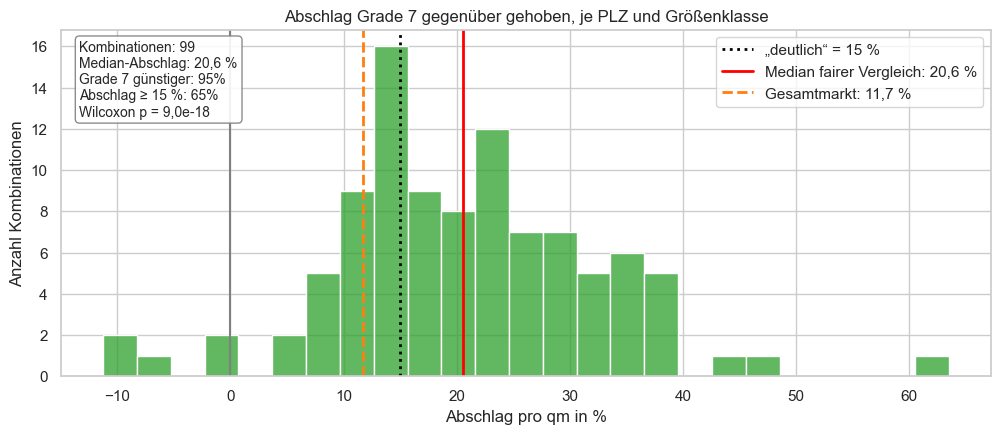

In [19]:
zellen = vergleich.groupby(["zipcode", "groesse", "Gruppe"], observed=True)["qm_preis"].agg(["median", "size"]).unstack()
zellen = zellen[(zellen["size"] >= 5).all(axis=1)]
zellen["abschlag"] = 100 * (1 - zellen[("median", "durchschnittlich (7)")] / zellen[("median", "gehoben (9–10)")])

fair = zellen["abschlag"].median()
anteil_fair = (zellen["abschlag"] > 0).mean()
anteil_15 = (zellen["abschlag"] >= 15).mean()
p_fair = stats.wilcoxon(zellen["abschlag"], alternative="greater").pvalue
print(f"Vergleichbare Kombinationen (PLZ × Größe): {len(zellen)}")
print(f"Median-Abschlag: {de(fair, 1)} %  | Grade 7 günstiger in {anteil_fair:.0%} der Fälle")
print(f"Abschlag mind. 15 % in {anteil_15:.0%} der Fälle")
print(f"Wilcoxon p = {p_de(p_fair)}")

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.histplot(zellen["abschlag"], bins=25, color="tab:green", ax=ax)
ax.axvline(0, color="gray")
ax.axvline(15, color="black", ls=":", lw=2, label="„deutlich“ = 15 %")
ax.axvline(fair, color="red", lw=2, label=f"Median fairer Vergleich: {de(fair, 1)} %")
ax.axvline(abschlag, color="tab:orange", lw=2, ls="--", label=f"Gesamtmarkt: {de(abschlag, 1)} %")
ax.set_title("Abschlag Grade 7 gegenüber gehoben, je PLZ und Größenklasse")
ax.set_xlabel("Abschlag pro qm in %")
ax.set_ylabel("Anzahl Kombinationen")
ax.legend(loc="upper right")
kennzahlen(ax, f"Kombinationen: {len(zellen)}\nMedian-Abschlag: {de(fair, 1)} %\n"
               f"Grade 7 günstiger: {anteil_fair:.0%}\nAbschlag ≥ 15 %: {anteil_15:.0%}\n"
               f"Wilcoxon p = {p_de(p_fair)}", x=0.02, ha="left")
plt.show()

**Kennzahlen:** 99 vergleichbare Kombinationen (PLZ × Größenklasse) · Median-Abschlag 20,6 % · Grade 7 günstiger in 95 % der Fälle · Abschlag von mind. 15 % in 65 % der Fälle · Wilcoxon p = 9,0 · 10⁻¹⁸

**Was bedeutet das?** Bei **gleicher Lage und gleicher Größe** ist Grade 7 pro qm im Median rund **21 %** günstiger, und das in **fast allen** Kombinationen. Das liegt klar über der 15-%-Grenze. **Für vergleichbare Häuser ist H3 bestätigt.**

---
## 7. Preisvergleich je Postleitzahl
Für die Präsentation zeigen wir den fairen Vergleich pro Postleitzahl. Wir nehmen nur Häuser mit **150–300 qm**, weil es in dieser Größe beide Gruppen gibt (und das ist auch die Größe, die Thomas sucht). Jede Zeile ist eine PLZ: **orange = Grade 7, blau = gehoben**. Je länger die graue Verbindung, desto mehr spart man dort. Die Grafik wird auch als HTML in `output/` gespeichert.

In [20]:
mittel = vergleich[vergleich["qm_living"].between(150, 300)]
plz = mittel.groupby(["zipcode", "Gruppe"])["qm_preis"].agg(["median", "size"]).unstack()
plz = plz[(plz["size"] >= 5).all(axis=1)]
plz = pd.DataFrame({"g7": plz[("median", "durchschnittlich (7)")], "geh": plz[("median", "gehoben (9–10)")]})
plz["abschlag"] = 100 * (1 - plz["g7"] / plz["geh"])
plz = plz.sort_values("geh")
namen_plz = "PLZ " + plz.index.astype(str)
n_guenstiger = (plz["abschlag"] > 0).sum()

fig = go.Figure()
for name, zeile in zip(namen_plz, plz.itertuples()):
    fig.add_trace(go.Scatter(x=[zeile.g7, zeile.geh], y=[name, name], mode="lines",
                             line=dict(color="lightgray", width=4), showlegend=False, hoverinfo="skip"))
fig.add_trace(go.Scatter(x=plz["g7"], y=namen_plz, mode="markers", name="durchschnittlich (Grade 7)",
                         marker=dict(size=11, color="#eb6834"), customdata=plz["abschlag"],
                         hovertemplate="%{y}<br>Grade 7: %{x:,.0f} $/qm<br>Abschlag: %{customdata:.0f} %<extra></extra>"))
fig.add_trace(go.Scatter(x=plz["geh"], y=namen_plz, mode="markers", name="gehoben (Grade 9–10)",
                         marker=dict(size=11, color="#2a78d6"),
                         hovertemplate="%{y}<br>gehoben: %{x:,.0f} $/qm<extra></extra>"))
fig.add_annotation(
    x=0.99, y=0.02, xref="paper", yref="paper", xanchor="right", yanchor="bottom", align="left", showarrow=False,
    bgcolor="white", bordercolor="gray", borderwidth=1,
    text=(f"<b>Kennzahlen (150–300 qm)</b><br>PLZ verglichen: {len(plz)}<br>"
          f"Grade 7 günstiger: {n_guenstiger} von {len(plz)}<br>"
          f"Median-Abschlag: {de(plz['abschlag'].median(), 1)} %<br>"
          f"Spanne: {de(plz['abschlag'].min())} % bis {de(plz['abschlag'].max())} %<br>"
          f"fairer Vergleich (PLZ × Größe): {de(fair, 1)} %"),
)
fig.update_layout(
    title=f"In {n_guenstiger} von {len(plz)} Postleitzahlen ist Grade 7 pro qm günstiger "
          f"(Median-Abschlag {de(plz['abschlag'].median())} %, Häuser 150–300 qm)",
    xaxis_title="Median-Preis pro qm ($)", height=max(550, 22 * len(plz)), template="plotly_white",
    legend=dict(orientation="h", y=1.02, x=0), separators=",.",
)
fig.write_html("output/h3_plz_vergleich_c.html")
fig.show()

**Kennzahlen (Häuser mit 150–300 qm):** 63 PLZ verglichen · Grade 7 in 58 von 63 PLZ günstiger · Median-Abschlag 12,5 % · Spanne −5 % bis 60 %

**Was sehen wir?** In fast jeder Postleitzahl liegt der orange Punkt (Grade 7) **links** vom blauen (gehoben), ist also günstiger. Der Median-Abschlag ist hier mit 12,5 % kleiner als im fairen Vergleich (20,6 %). Das liegt daran, dass wir hier die ganze Spanne 150–300 qm zusammenfassen: Innerhalb dieser Spanne sind die Grade-7-Häuser deutlich kleiner (Median 183 qm gegenüber 251 qm) und damit pro qm etwas teurer. Die Grafik zeigt also vor allem die **Richtung**, die genaue Höhe kommt aus Abschnitt 6. Gleichzeitig sieht man: Ein Grade-7-Haus in einer teuren PLZ (oben) kostet pro qm mehr als ein gehobenes Haus in einer günstigen PLZ (unten). **Die Lage wirkt stärker als die Ausstattung.**

---
## 8. Fazit

| Vergleich | Abschlag Grade 7 gegenüber gehoben | deutlich (mind. 15 %)? |
|---|---|---|
| Gesamtmarkt (Hypothese wörtlich) | ca. 12 %, signifikant (gesichert 10,6 %) | nein |
| Fair: gleiche PLZ und gleiche Größe | ca. 21 %, in 95 % der Fälle günstiger | ja |
| **Ergebnis** | **H3 bestätigt für vergleichbare Häuser**, am Gesamtmarkt nur schwach | |

**Erkenntnisse**
1. Am Gesamtmarkt ist der Unterschied klein: Grade 7 ist pro qm nur ca. 12 % günstiger, und in 4 von 10 Paaren sogar teurer.
2. Die Hausgröße verdeckt den Effekt: Gehobene Häuser sind fast doppelt so groß, und große Häuser sind pro qm günstiger.
3. Bei gleicher Lage und Größe spart man rund 20 % pro qm mit durchschnittlicher Bauqualität. Das passt gut zum Baukostenunterschied von ca. 17 %.

**Empfehlungen für Thomas**
1. Auf gehobene Ausstattung verzichten: In derselben Nachbarschaft bekommt er bei gleicher Größe rund 20 % mehr Fläche fürs Geld. Bei 200 qm sind das grob 100.000 $.
2. qm-Preise nur innerhalb einer Nachbarschaft vergleichen: Über Stadtteile hinweg ist „Grade 7 = günstig“ nicht verlässlich, weil die Lage stärker wirkt als die Ausstattung.
3. Alter mit einrechnen: Grade-7-Häuser sind im Median rund 30 Jahre älter. Renovierungs- und Energiekosten sollte er einplanen.

**Grenzen:** `grade` ist eine Einstufung des Assessors, keine Messung · nur Kombinationen mit genug Häusern aus beiden Gruppen sind vergleichbar · Markt von 2014/15 · keine Aussage über Ursache und Wirkung.